# Apresentação - Parte 1


# Introdução

A pesquisa PNAD Continua coleta dados demográficos a nível de domícilio por pessoa. Com esses dados podem ser realizados diversos estudos sociais para investigar como variaveis sociais podem ser estudadas através de outras. Neste estudo, verificamos como variáveis como sexo, idade, tempo de trabalho, pessoas no domicílio e anos de estudo de uma pessoa podem descrever sua renda. 

## Instalação ou carregamento de pacotes

In [54]:
pacotes <- c("car", "MASS", "nortest", "fBasics", "lmtest", "PNADcIBGE", "tidyverse", "ggplot2", "dplyr")

for (pacote in pacotes) {
  if (!requireNamespace(pacote, quietly = TRUE)) {
    install.packages(pacote, repos = "https://cloud.r-project.org")
  }

  carregou <- suppressPackageStartupMessages(
    require(pacote, character.only = TRUE)
  )

  if (carregou) {
    cat(pacote, ": carregado com sucesso\n")
  } else {
    cat(pacote, ": ERRO ao carregar\n")
  }
}

car : carregado com sucesso
MASS : carregado com sucesso
nortest : carregado com sucesso
fBasics : carregado com sucesso
lmtest : carregado com sucesso
PNADcIBGE : carregado com sucesso
tidyverse : carregado com sucesso
ggplot2 : carregado com sucesso
dplyr : carregado com sucesso


# Carregamento dos dados

In [55]:
if (file.exists("pnadc_2026_SEMESTRE1_brutos.rds")) {
  dados_pnadc_brutos <- readRDS("pnadc_2026_SEMESTRE1_brutos.rds")
  cat("Dados carregados com sucesso.\n")
} else {
  cat("Arquivo local não encontrado. Baixando o primeiro semestre de 2026...\n")
  dados_pnadc_brutos <- get_pnadc(year = 2026, quarter = 1, design = FALSE, labels = FALSE)
  saveRDS(dados_pnadc_brutos, "pnadc_2026_SEMESTRE1_brutos.rds")
}

Arquivo local não encontrado. Baixando o primeiro semestre de 2026...


# Separação e limpeza dos dados

In [41]:
dados_regressao <- dados_pnadc_brutos %>%
  select(
    renda = VD4020,
    sexo = V2007,
    idade = V2009,
    anos_estudo = VD3005,
    horas_trabalhadas = V4039,
    numero_pessoas_domicilio = V2001
  ) %>%
  filter(
    renda > 0
  ) %>%
  filter(complete.cases(.))

In [42]:
head(dados_regressao)

renda,sexo,idade,anos_estudo,horas_trabalhadas,numero_pessoas_domicilio
<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
1500,1,52,06,48,1
1600,2,59,05,36,2
7600,2,64,12,40,4
2000,1,41,12,44,4
1800,2,24,12,44,4
2500,2,42,12,40,4


# Gráficos

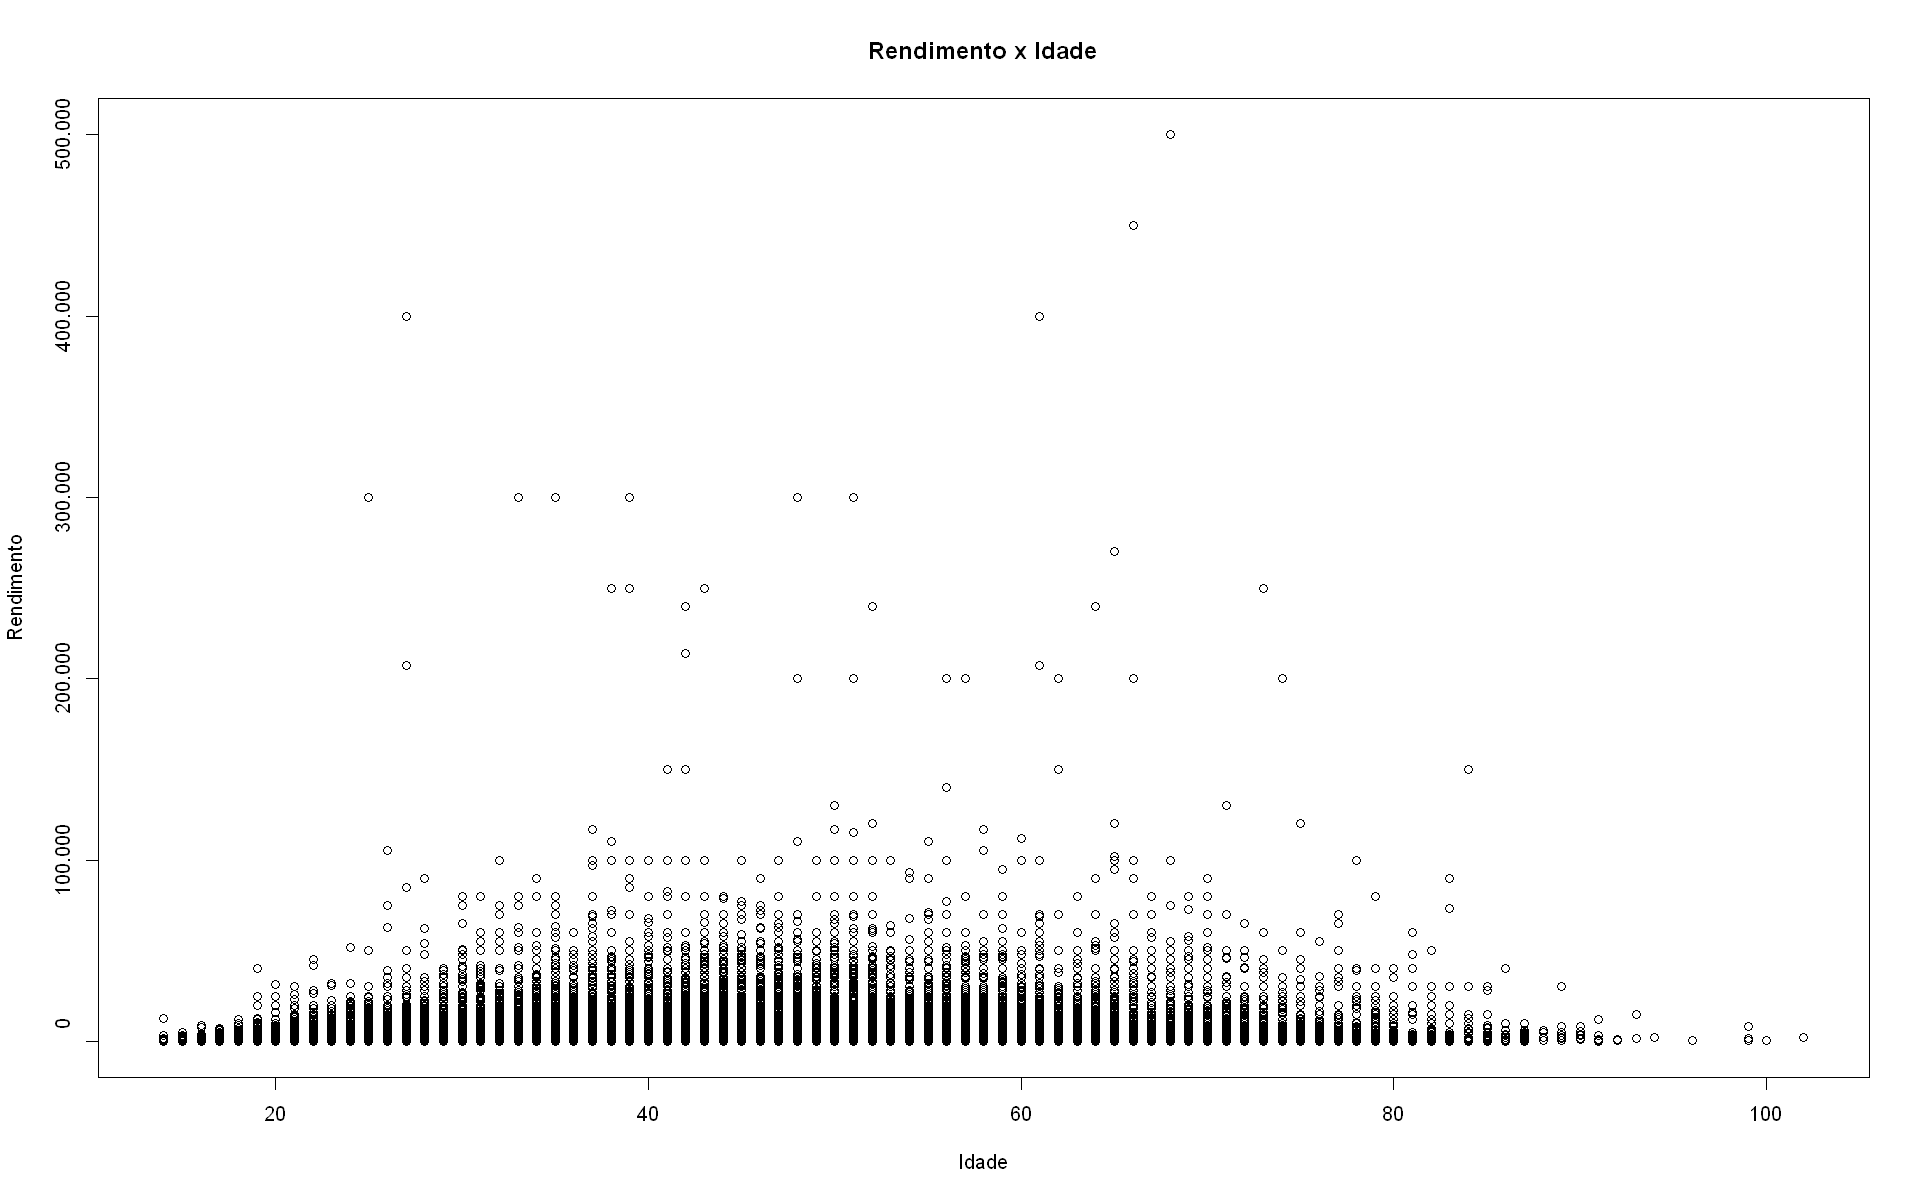

In [43]:
plot(
  dados_regressao$idade,
  dados_regressao$renda,
  xlab = "Idade",
  ylab = "Rendimento",
  main = "Rendimento x Idade",
  yaxt = "n"
)

axis(
  side = 2,
  at = axTicks(2),
  labels = format(axTicks(2), big.mark = ".", decimal.mark = ",", scientific = FALSE)
)

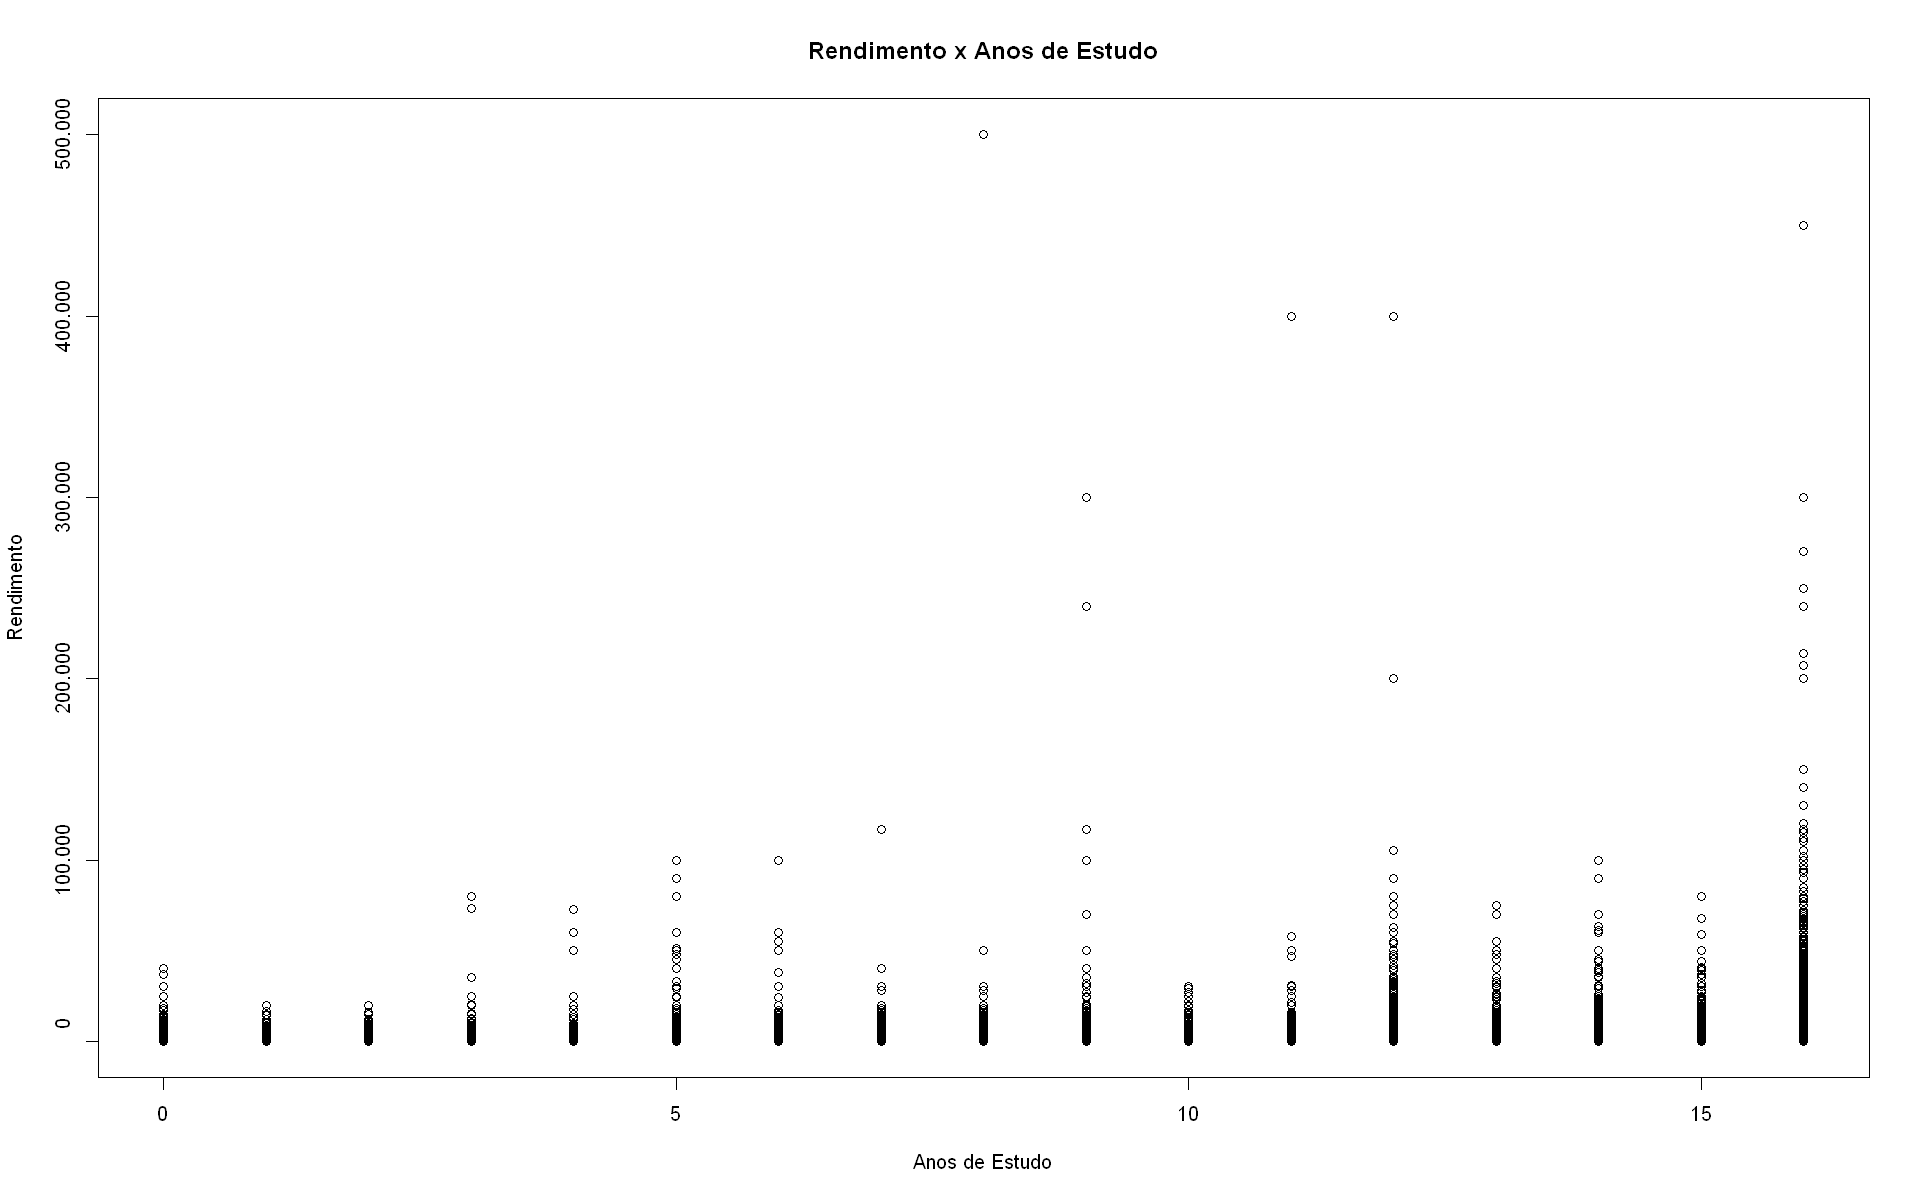

In [44]:
plot(
  dados_regressao$anos_estudo,
  dados_regressao$renda,
  xlab = "Anos de Estudo",
  ylab = "Rendimento",
  main = "Rendimento x Anos de Estudo",
  yaxt = "n"
)

axis(
  side = 2,
  at = axTicks(2),
  labels = format(axTicks(2), big.mark = ".", decimal.mark = ",", scientific = FALSE)
)

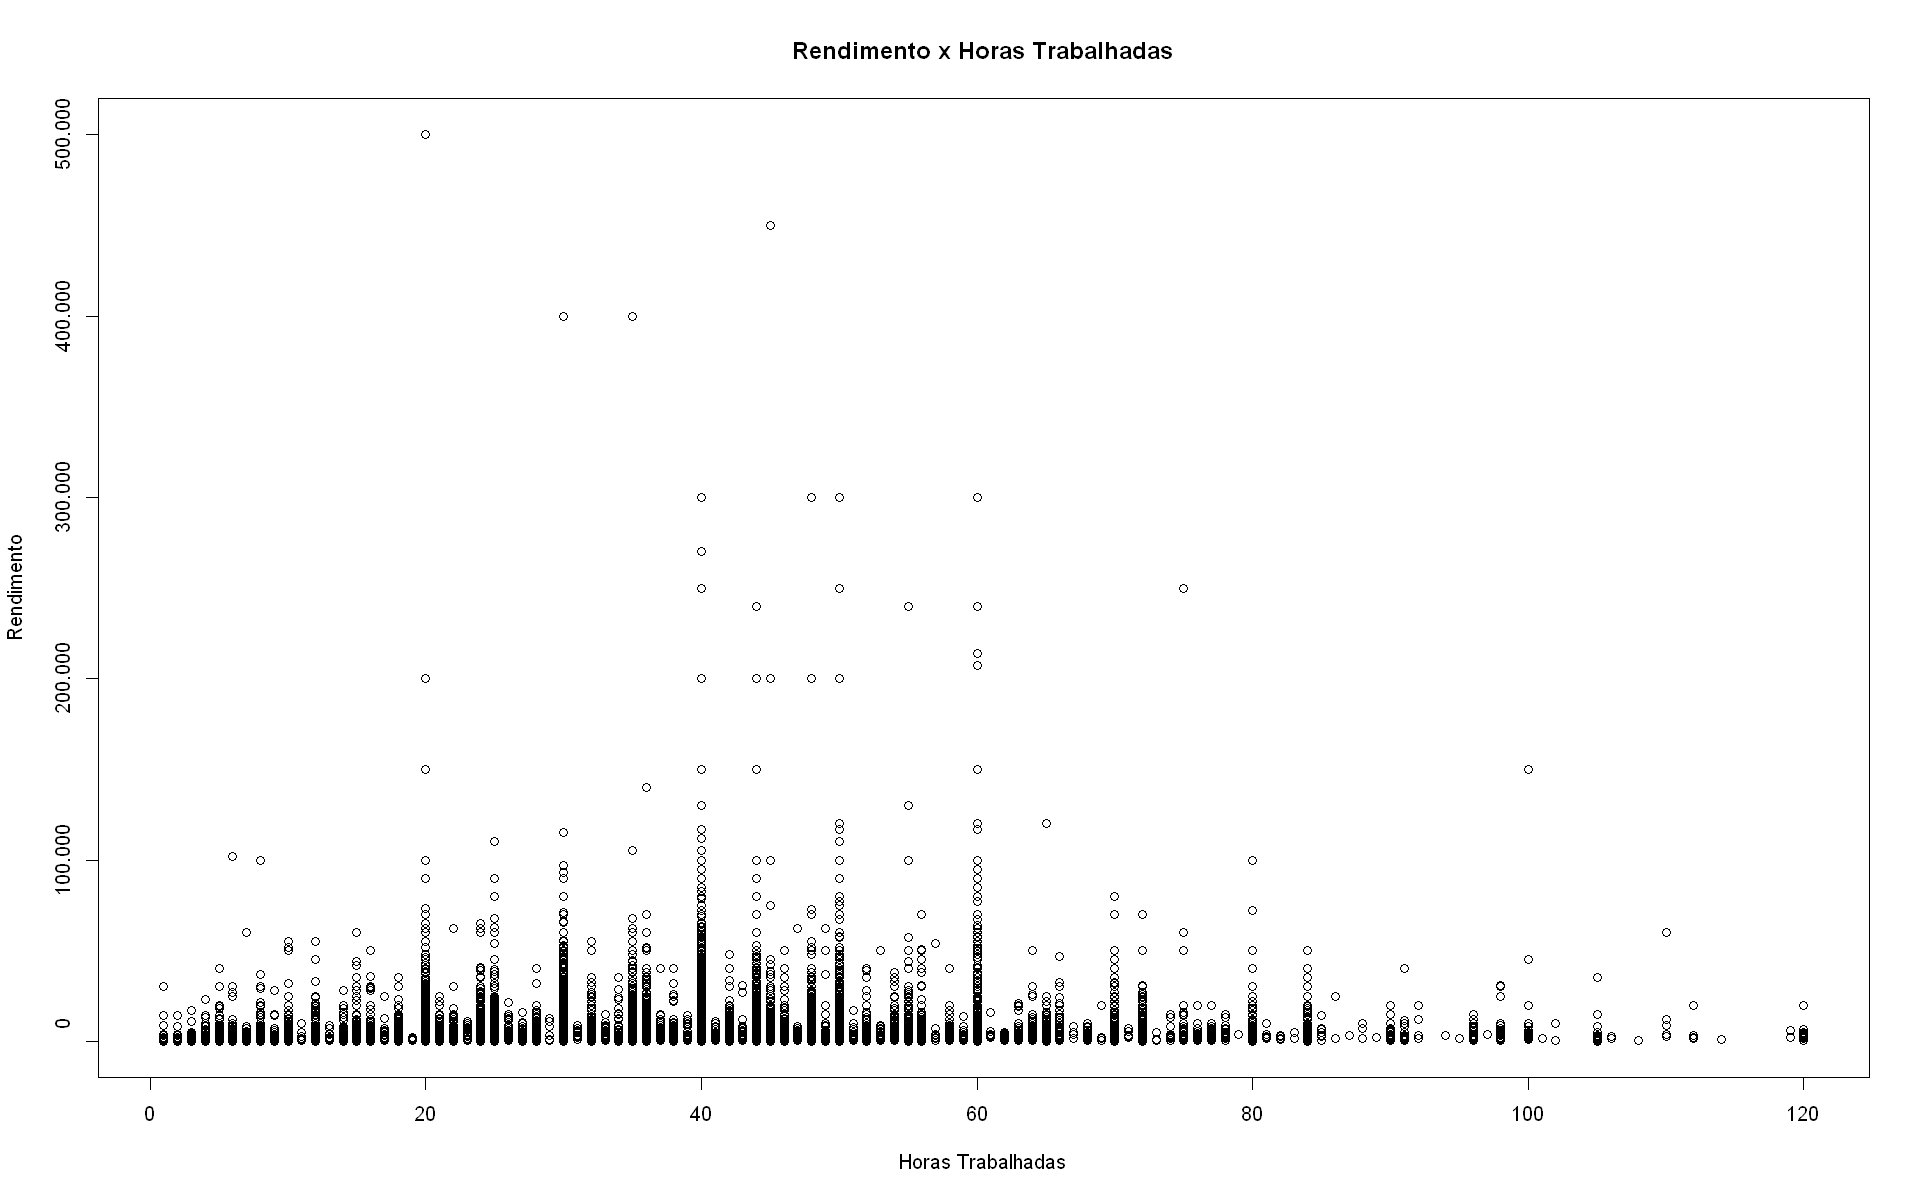

In [45]:
plot(
  dados_regressao$horas_trabalhadas,
  dados_regressao$renda,
  xlab = "Horas Trabalhadas",
  ylab = "Rendimento",
  main = "Rendimento x Horas Trabalhadas",
  yaxt = "n"
)

axis(
  side = 2,
  at = axTicks(2),
  labels = format(axTicks(2), big.mark = ".", decimal.mark = ",", scientific = FALSE)
)

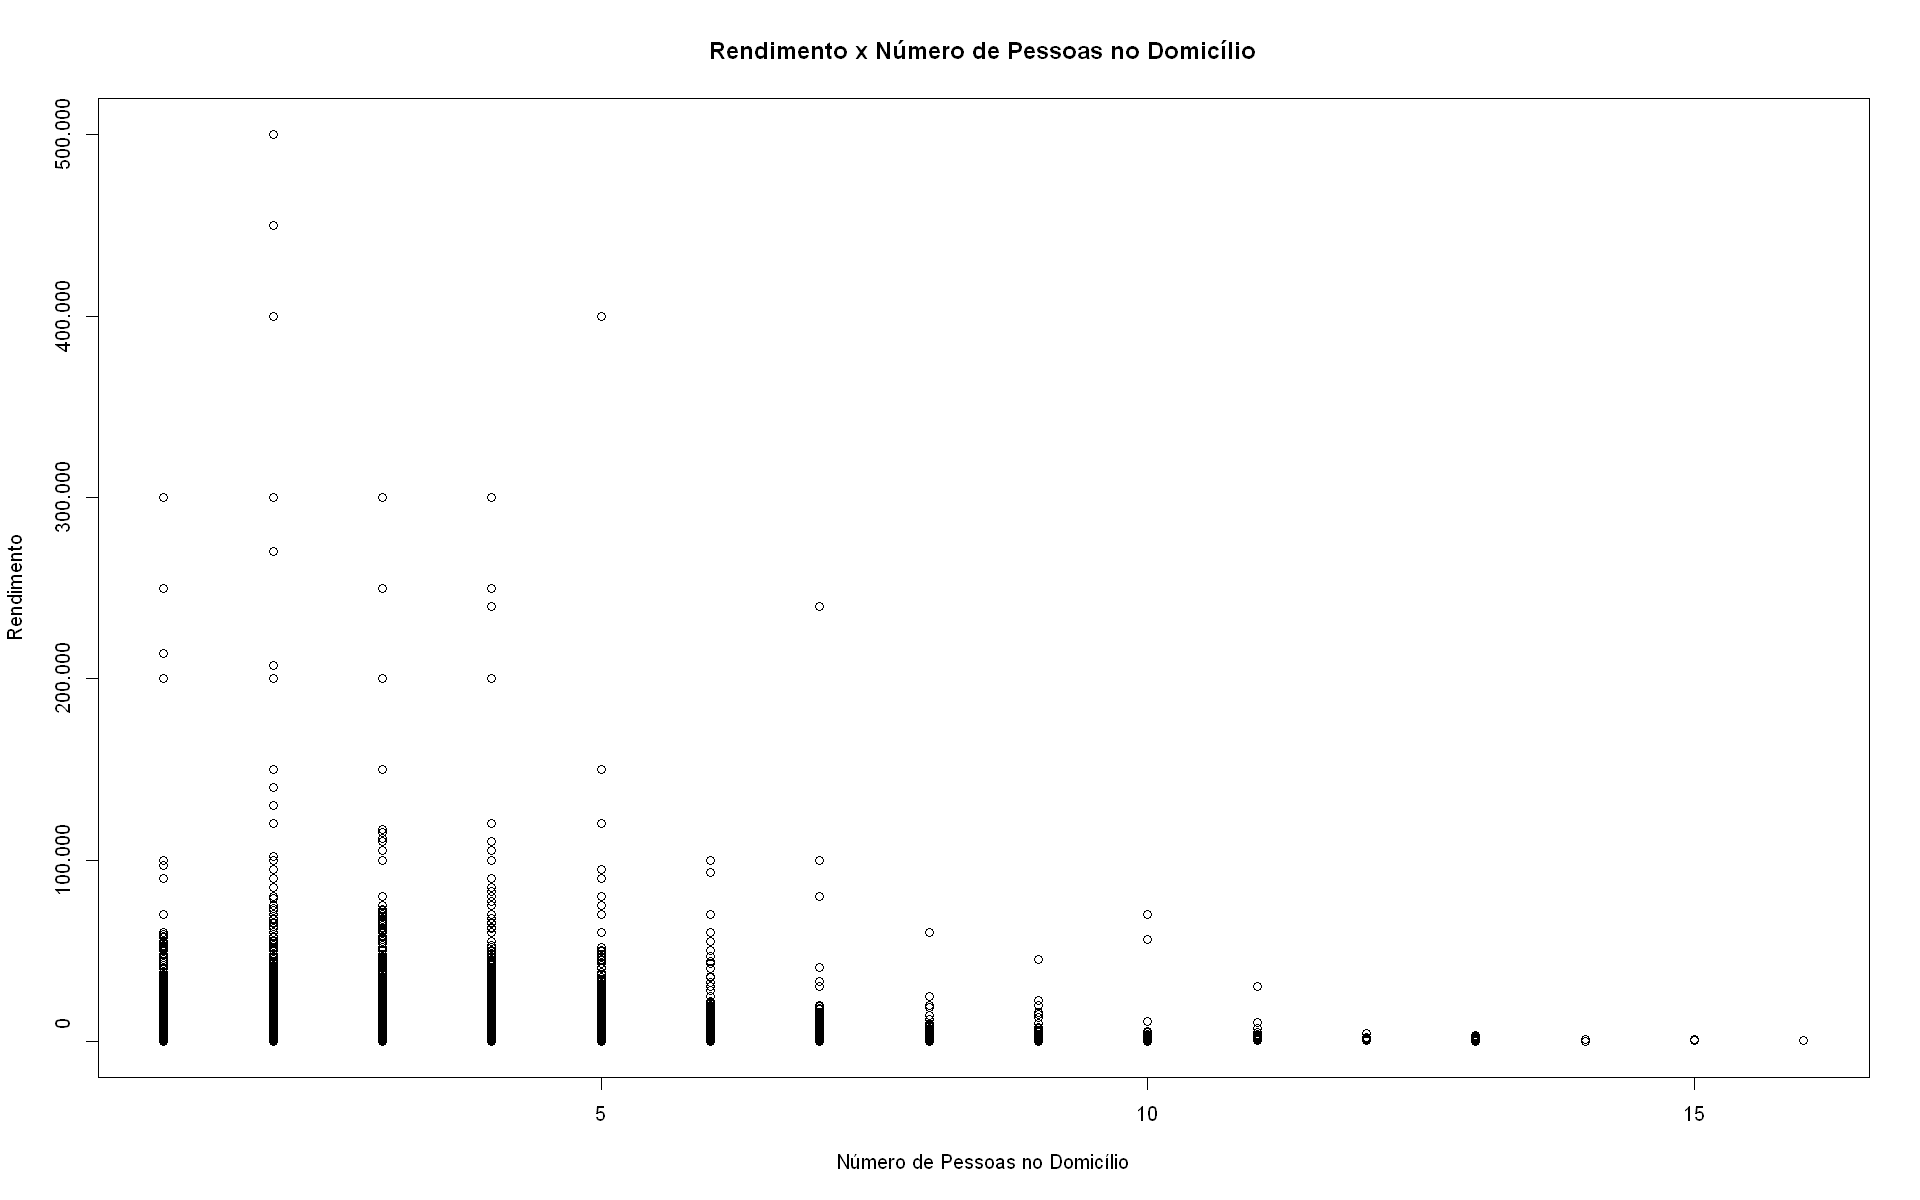

In [46]:
plot(
  dados_regressao$numero_pessoas_domicilio,
  dados_regressao$renda,
  xlab = "Número de Pessoas no Domicílio",
  ylab = "Rendimento",
  main = "Rendimento x Número de Pessoas no Domicílio",
  yaxt = "n"
)

axis(
  side = 2,
  at = axTicks(2),
  labels = format(axTicks(2), big.mark = ".", decimal.mark = ",", scientific = FALSE)
)

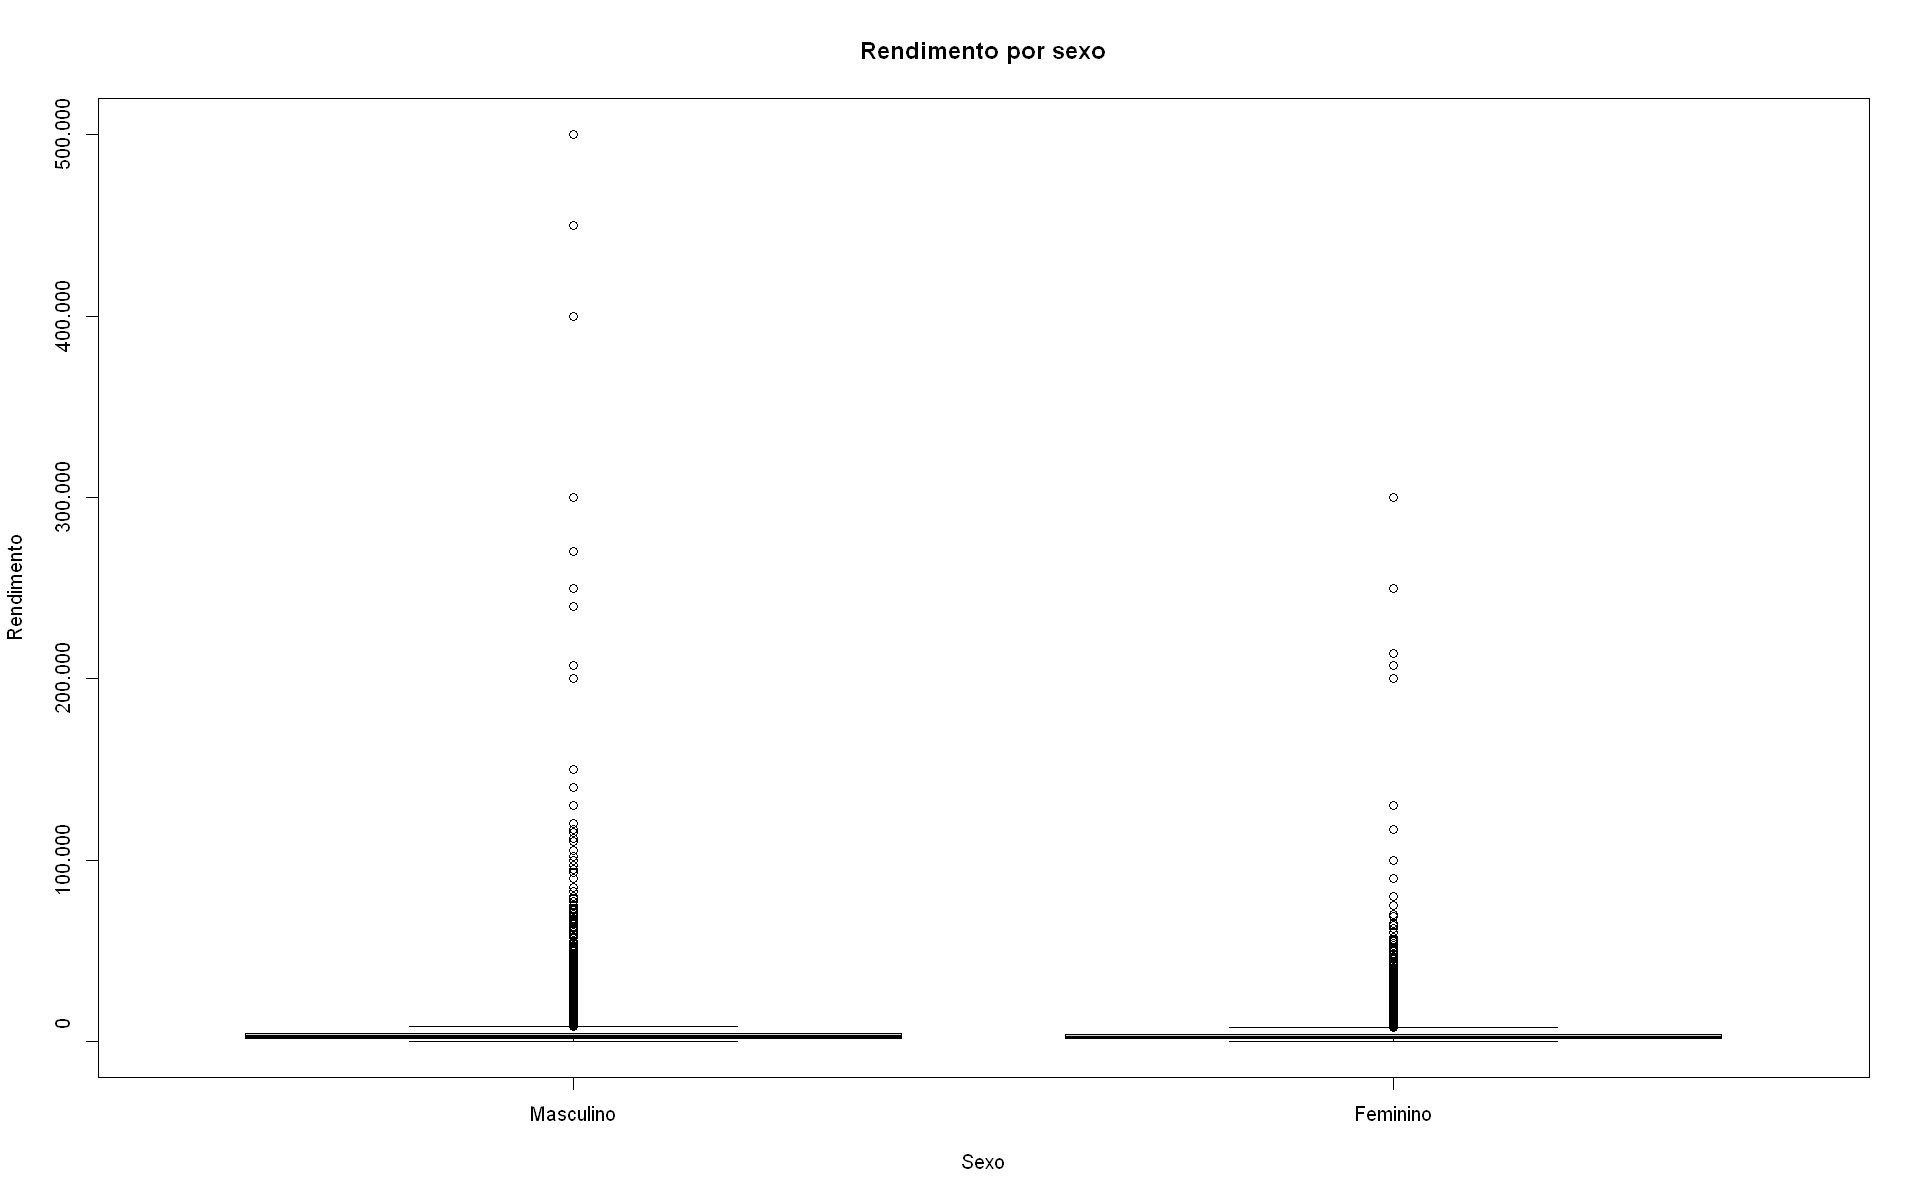

In [47]:
boxplot(
  dados_regressao$renda ~ dados_regressao$sexo,
  data = dados_regressao,
  xlab = "Sexo",
  ylab = "Rendimento",
  main = "Rendimento por sexo",
  names = c("Masculino", "Feminino"),
  yaxt = "n"
)

axis(
  side = 2,
  at = axTicks(2),
  labels = format(axTicks(2), big.mark = ".", decimal.mark = ",", scientific = FALSE)
)

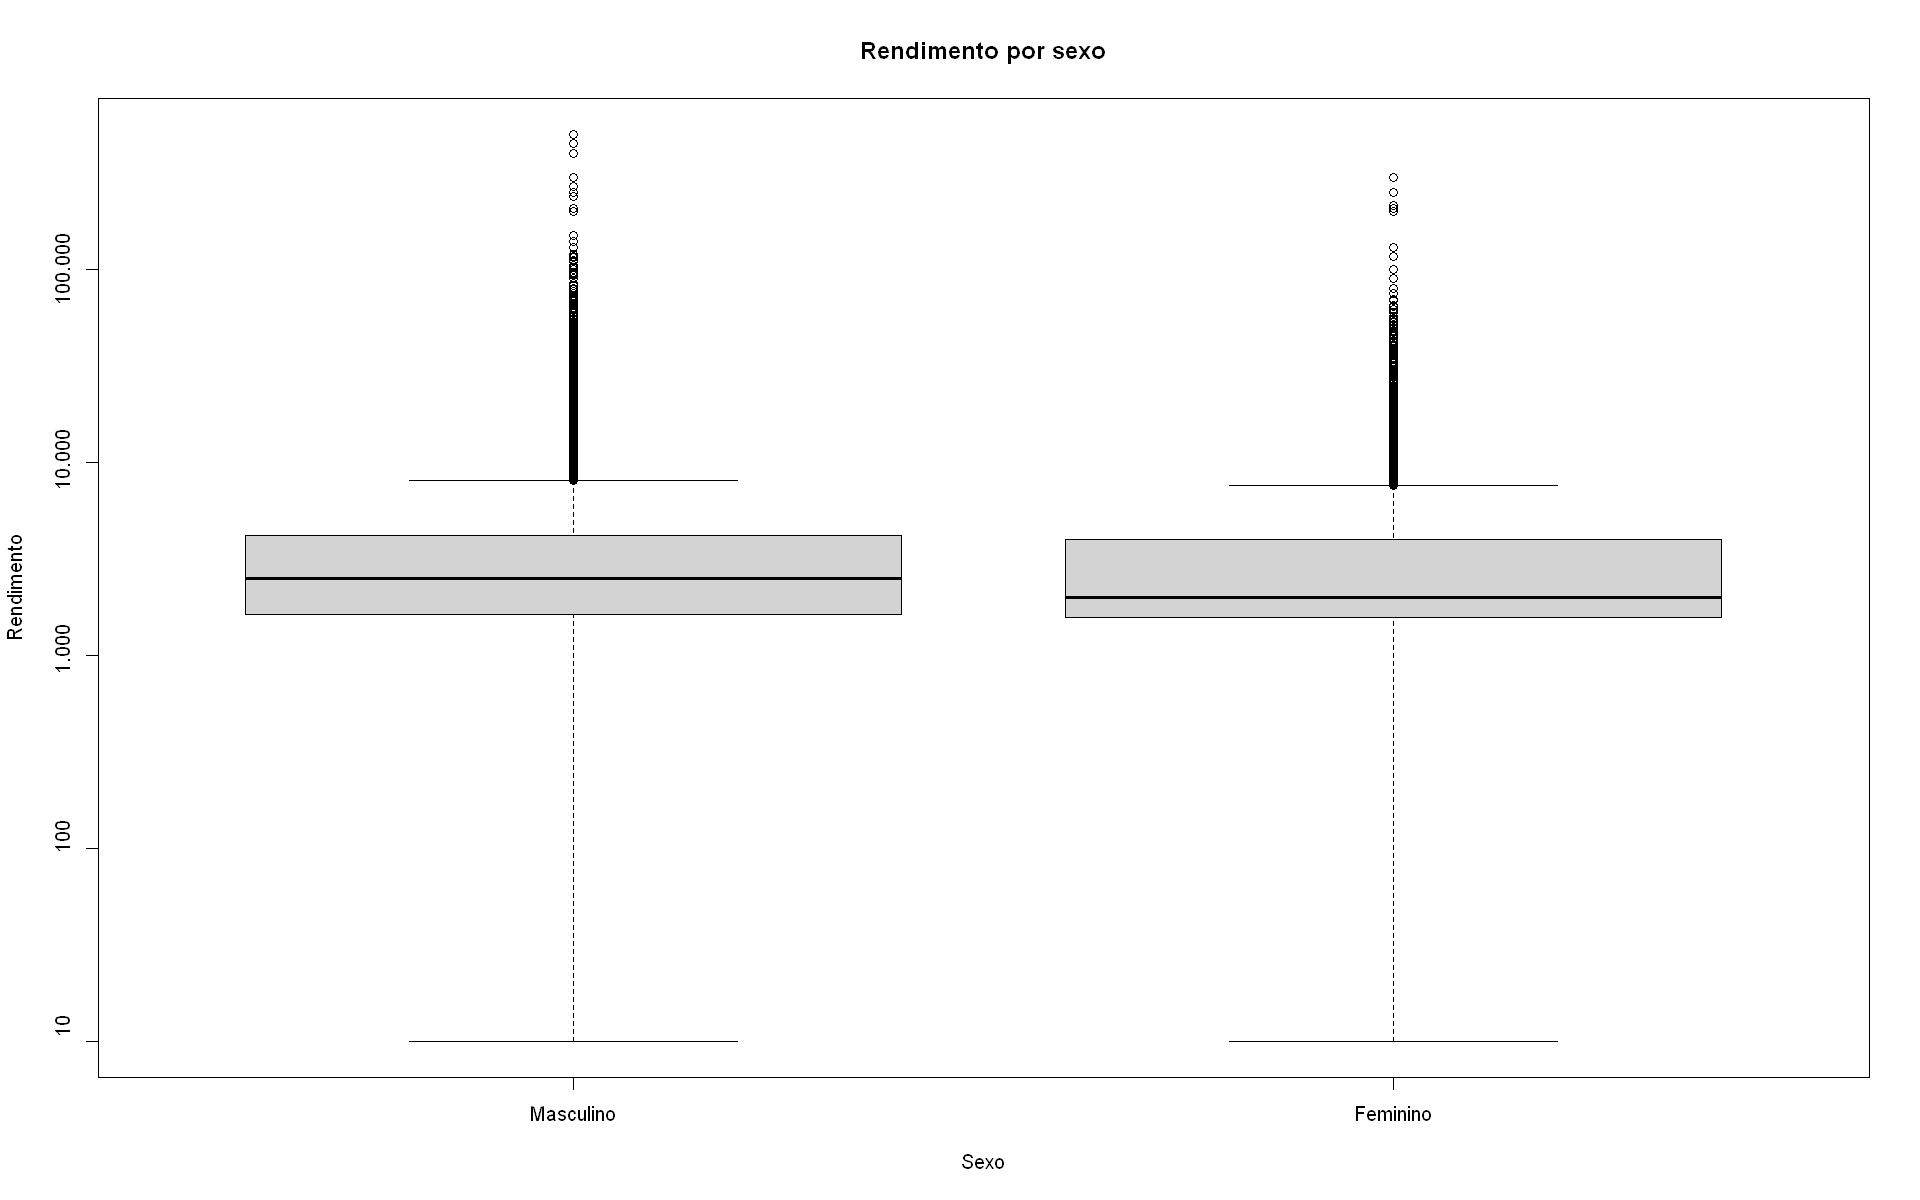

In [48]:
boxplot(
  dados_regressao$renda ~ dados_regressao$sexo,
  data = dados_regressao,
  log = "y",
  xlab = "Sexo",
  ylab = "Rendimento",
  main = "Rendimento por sexo",
  names = c("Masculino", "Feminino"),
  yaxt = "n"
)

axis(
  side = 2,
  at = axTicks(2),
  labels = format(axTicks(2), big.mark = ".", decimal.mark = ",", scientific = FALSE)
)

# Regressão

In [51]:
modelo <- lm(renda ~ idade, data = dados_regressao)
summary(modelo)


Call:
lm(formula = renda ~ idade, data = dados_regressao)

Residuals:
   Min     1Q Median     3Q    Max 
 -6182  -2374  -1374    238 494939 

Coefficients:
            Estimate Std. Error t value            Pr(>|t|)    
(Intercept) 2041.070     43.909   46.48 <0.0000000000000002 ***
idade         44.410      1.007   44.09 <0.0000000000000002 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 6373 on 217497 degrees of freedom
Multiple R-squared:  0.00886,	Adjusted R-squared:  0.008856 
F-statistic:  1944 on 1 and 217497 DF,  p-value: < 0.00000000000000022


In [34]:
modelo_log <- lm(log(renda) ~ idade, data = dados_regressao)
summary(modelo_log)


Call:
lm(formula = log(renda) ~ idade, data = dados_regressao)

Residuals:
    Min      1Q  Median      3Q     Max 
-5.6462 -0.4154 -0.0336  0.5362  5.2129 

Coefficients:
            Estimate Std. Error t value            Pr(>|t|)    
(Intercept) 7.575168   0.006625 1143.35 <0.0000000000000002 ***
idade       0.004916   0.000152   32.35 <0.0000000000000002 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.9616 on 217497 degrees of freedom
Multiple R-squared:  0.004788,	Adjusted R-squared:  0.004784 
F-statistic:  1046 on 1 and 217497 DF,  p-value: < 0.00000000000000022


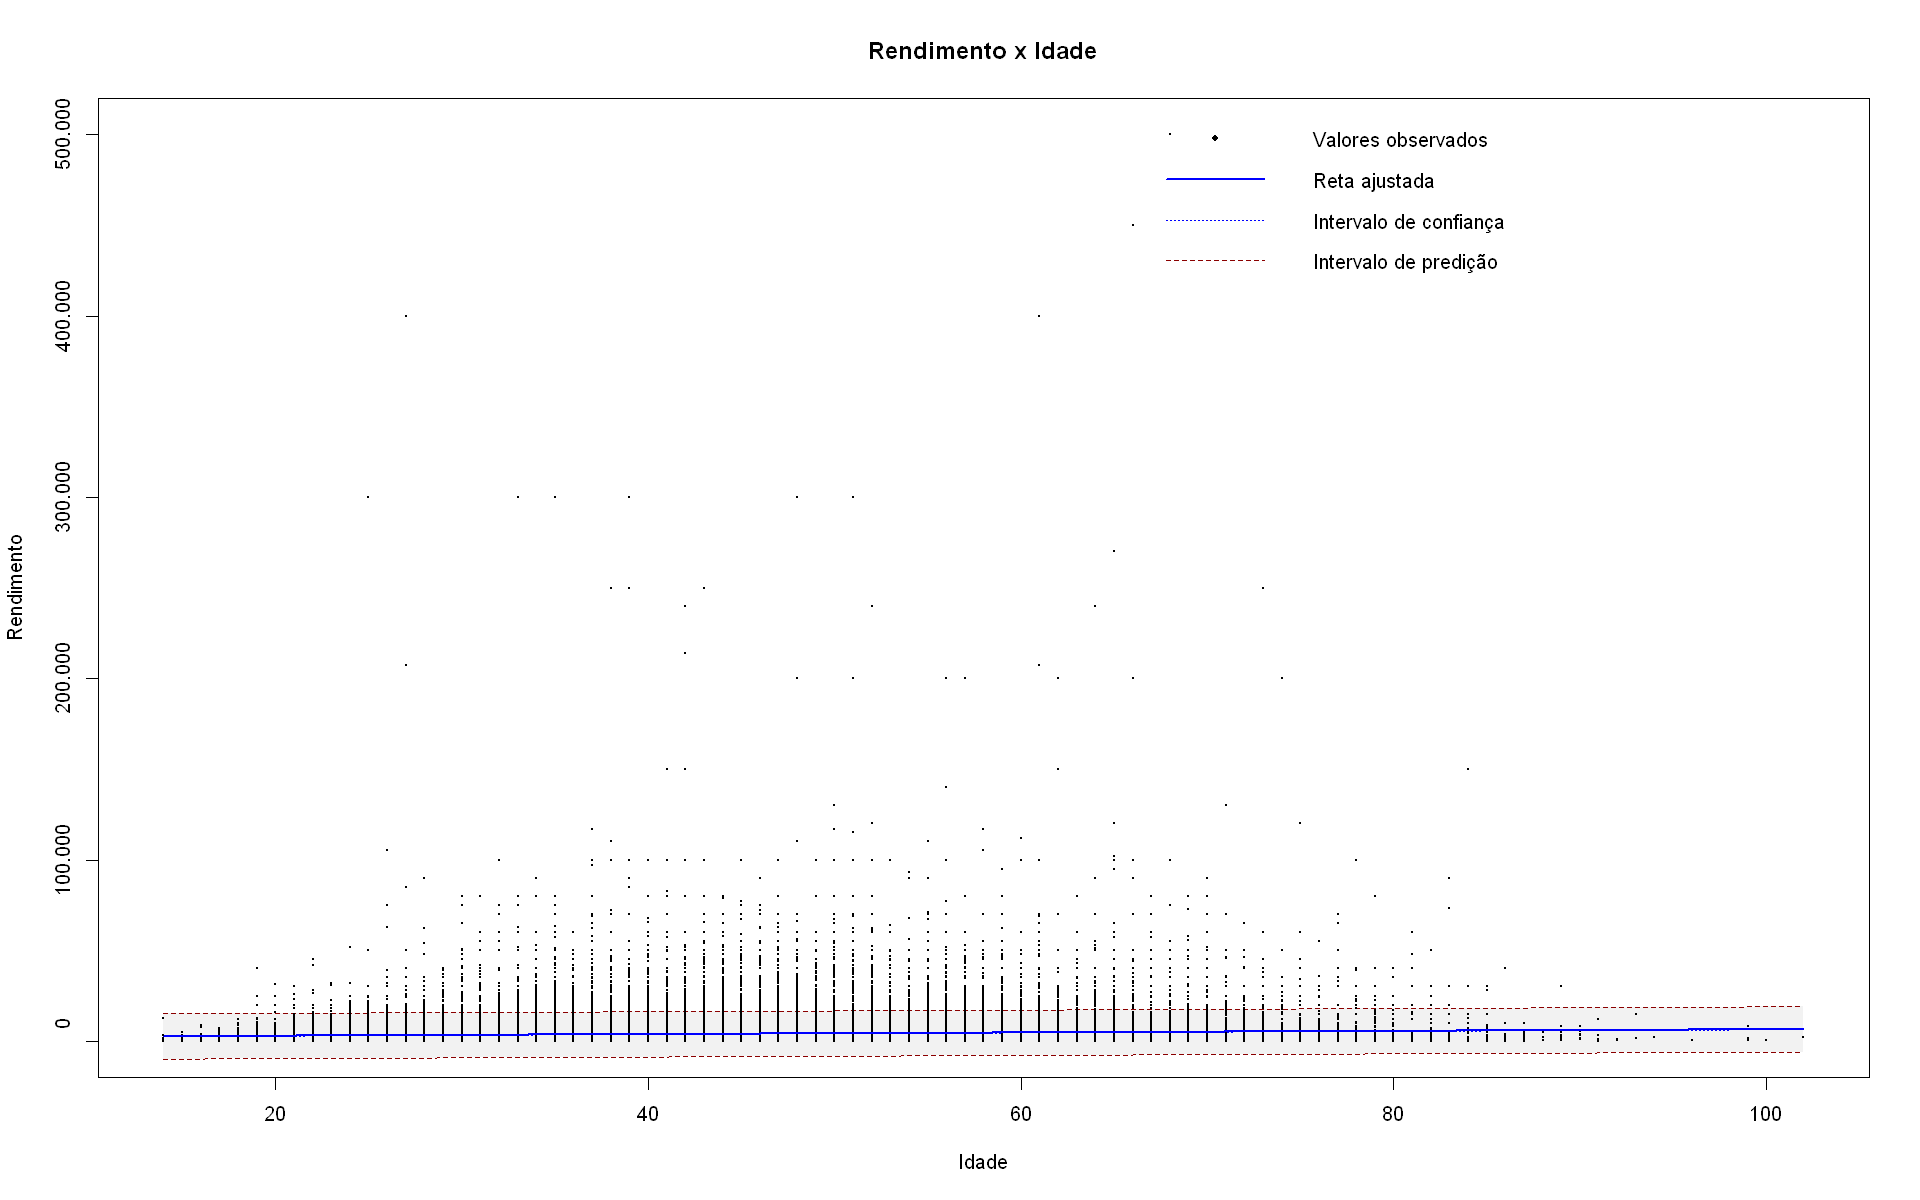

In [ ]:
options(repr.plot.width = 16, repr.plot.height = 10)

if (!identical(all.vars(formula(modelo)), c("renda", "idade"))) {
  modelo <- lm(renda ~ idade, data = dados_regressao)
}

idades <- seq(
  min(dados_regressao$idade, na.rm = TRUE),
  max(dados_regressao$idade, na.rm = TRUE),
  length.out = 100
)

dados_predicao <- setNames(
  data.frame(idade = idades),
  names(model.frame(modelo))[2]
)

intervalo_confianca <- predict(
  modelo,
  newdata = dados_predicao,
  interval = "confidence",
  level = 0.95
)

intervalo_predicao <- predict(
  modelo,
  newdata = dados_predicao,
  interval = "prediction",
  level = 0.95
)

options(scipen = 999)
plot(
  dados_regressao$idade,
  dados_regressao$renda,
  type = "n",
  xlab = "Idade",
  ylab = "Rendimento",
  main = "Rendimento x Idade",
  yaxt = "n"
)

axis(
  side = 2,
  at = axTicks(2),
  labels = format(axTicks(2), big.mark = ".", decimal.mark = ",", scientific = FALSE)
)

polygon(
  c(rev(idades), idades),
  c(rev(intervalo_predicao[, "lwr"]), intervalo_predicao[, "upr"]),
  col = "grey95",
  border = NA
)

polygon(
  c(rev(idades), idades),
  c(rev(intervalo_confianca[, "lwr"]), intervalo_confianca[, "upr"]),
  col = "grey75",
  border = NA
)

lines(idades, intervalo_predicao[, "lwr"], col = "darkred", lty = 2, lwd = 1.5)
lines(idades, intervalo_predicao[, "upr"], col = "darkred", lty = 2, lwd = 1.5)

lines(idades, intervalo_confianca[, "lwr"], col = "blue", lty = 3, lwd = 1.5)
lines(idades, intervalo_confianca[, "upr"], col = "blue", lty = 3, lwd = 1.5)

points(dados_regressao$idade, dados_regressao$renda, pch = 20, cex = 0.2)
lines(idades, intervalo_confianca[, "fit"], col = "blue", lwd = 2)

legend(
  "topright",
  legend = c("Valores observados", "Reta ajustada", "Intervalo de confiança", "Intervalo de predição"),
  col = c("black", "blue", "blue", "darkred"),
  lty = c(NA, 1, 3, 2),
  lwd = c(NA, 2, 1.5, 1.5),
  pch = c(20, NA, NA, NA),
  bty = "n"
)

# Equação da reta de regressão ajustada:

$$Renda = 2041,070 + 44,410*Idade$$

# Análise gráfica das suposições do modelo

[1] 69324 87568

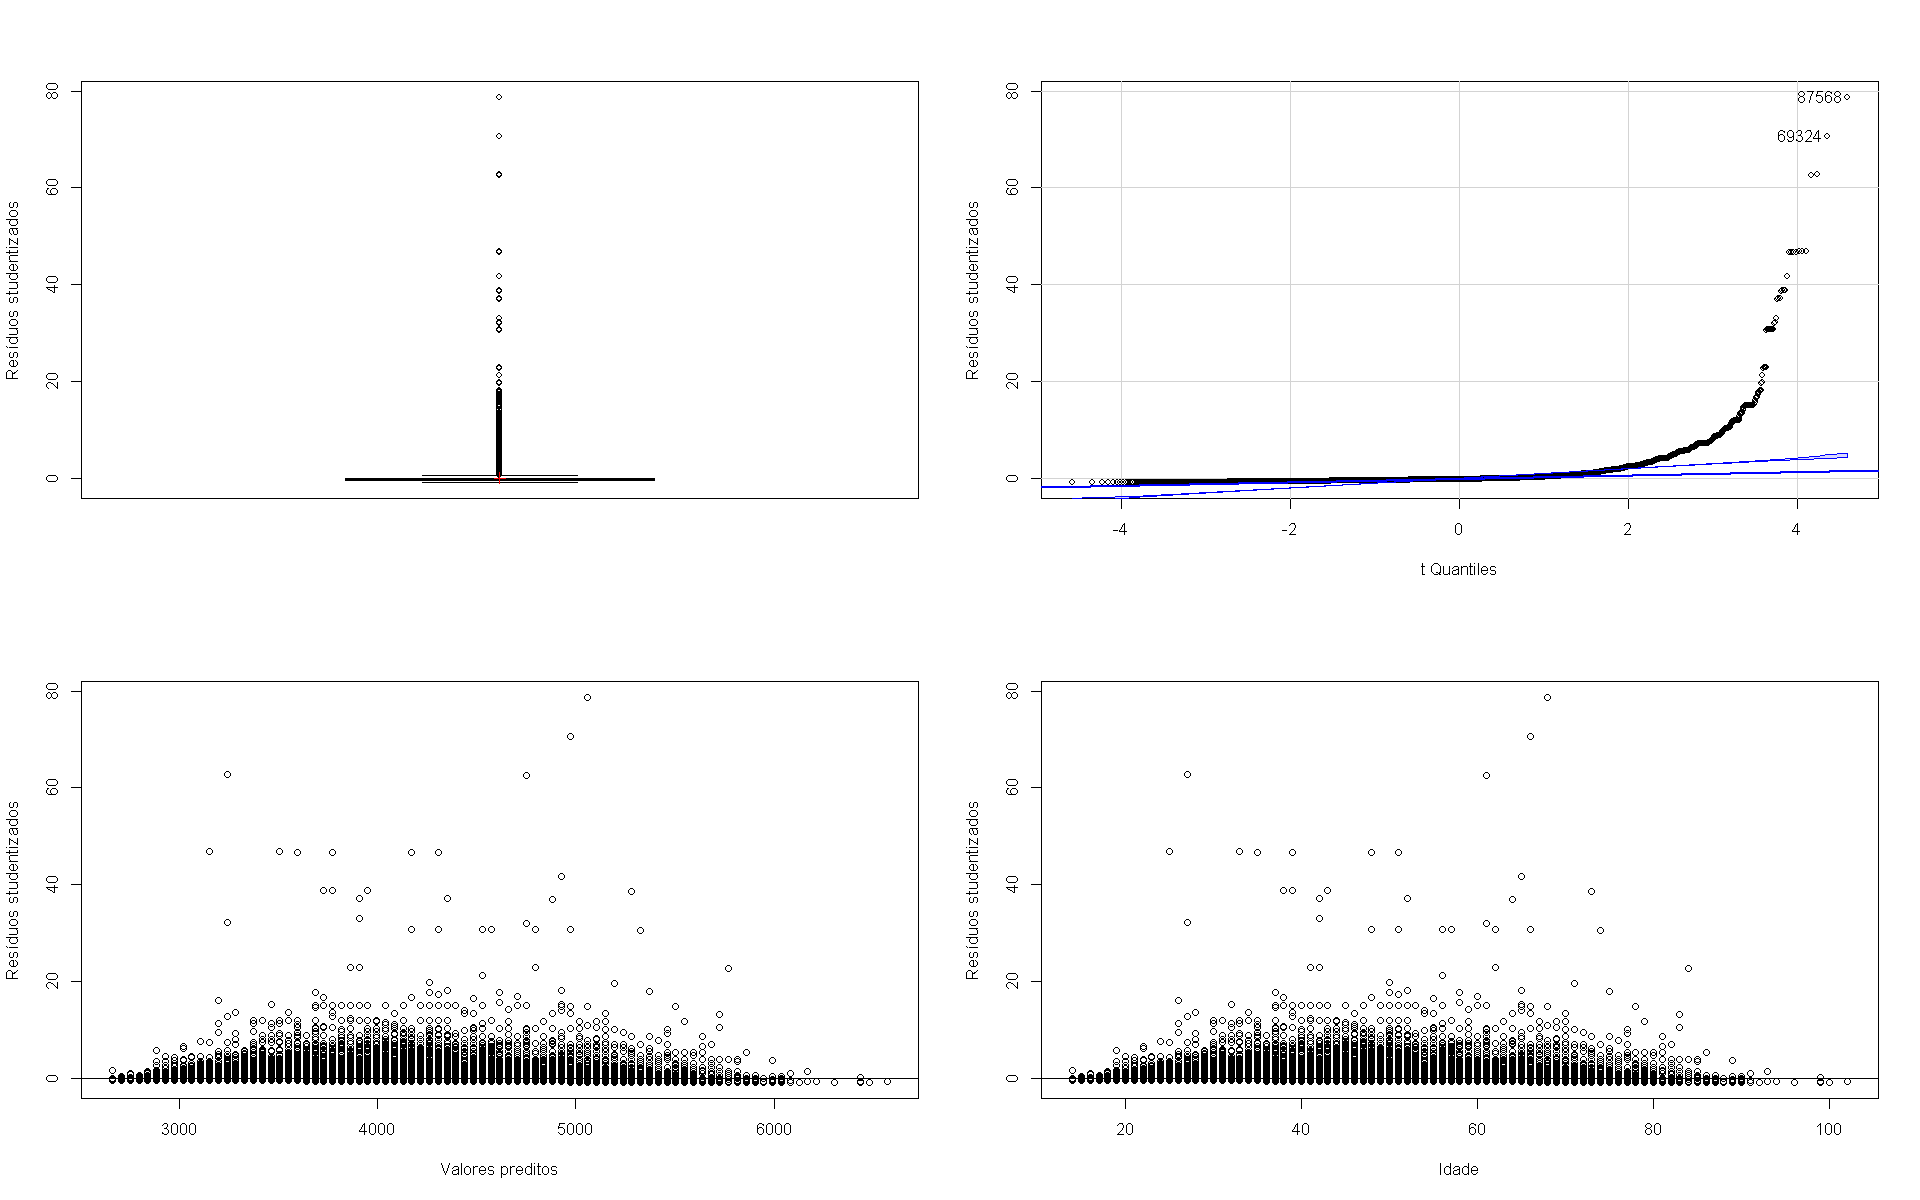

In [53]:
preditos <- predict(modelo);  # valores preditos ou previstos
residuos <- resid(modelo);      # resíduos
r_studentizado <- rstudent(modelo)    # esses resíduos têm propriedades melhores (usados no estudo de influência)

par(mfrow=c(2,2)) # criando um painel para 4 gráficos
boxplot(r_studentizado, ylab="Resíduos studentizados") # diagrama de caixas dos resíduos padronizados
points(mean(r_studentizado), col="red", pch=3)

car::qqPlot(modelo, envelope=0.95, ylab="Resíduos studentizados")

plot(preditos, r_studentizado, xlab="Valores preditos", ylab="Resíduos studentizados")
abline(h=0)

plot(dados_regressao$idade, r_studentizado, xlab="Idade", ylab="Resíduos studentizados")
abline(h=0)

par(mfrow=c(1,1)) #retomando ao default